In [1]:

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from itertools import combinations
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from ultralytics import SAM

device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

image_path = "../images/000000114269.jpg"

processor = AutoProcessor.from_pretrained(
    "IDEA-Research/grounding-dino-tiny"
)

dino = AutoModelForZeroShotObjectDetection.from_pretrained(
    "IDEA-Research/grounding-dino-tiny"
).to(device).eval()

sam = SAM("models/sam2.1_t.pt")

print("Device:", device)


def grounding_detect(image_rgb, prompt, box_threshold=0.20,
                     text_threshold=0.20):
    """Detect objects using a text prompt."""
    pil_image = Image.fromarray(image_rgb)

    inputs = processor(
        images=pil_image,
        text=prompt,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = dino(**inputs)

    result = processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=box_threshold,
        text_threshold=text_threshold,
        target_sizes=[pil_image.size[::-1]]
    )[0]

    return {
        "boxes": result["boxes"].cpu().numpy(),
        "scores": result["scores"].cpu().numpy(),
    }


def sam_segment(image_rgb, boxes):
    """Segment bounding-box prompts with SAM 2.1."""
    h, w = image_rgb.shape[:2]

    if len(boxes) == 0:
        return []

    results = sam.predict(
        source=image_rgb,
        bboxes=np.asarray(boxes).tolist(),
        verbose=False,
        device=device
    )

    if not results or results[0].masks is None:
        return []

    masks = results[0].masks.data.cpu().numpy()

    output = []
    for mask in masks:
        if mask.shape != (h, w):
            mask = cv2.resize(
                mask.astype(np.float32),
                (w, h),
                interpolation=cv2.INTER_NEAREST
            )
        output.append(mask > 0.5)

    return output


def mask_centroid(mask):
    ys, xs = np.where(mask)

    if len(xs) == 0:
        return None

    return (float(xs.mean()), float(ys.mean()))


def distance(p1, p2):
    return float(np.linalg.norm(
        np.array(p1) - np.array(p2)
    ))


/Users/yun/anaconda3/envs/animal-metrology/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1101 13:35:32.987000 83346 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 978/978 [00:00<00:00, 5801.00it/s]


Device: mps


In [2]:

# Read input image
image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise FileNotFoundError(image_path)

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
H, W = image_rgb.shape[:2]

# STEP 1: Detect animals using text
animal_det = grounding_detect(
    image_rgb,
    prompt="dog. cat.",
    box_threshold=0.20,
    text_threshold=0.20
)

animal_boxes = animal_det["boxes"]
animal_scores = animal_det["scores"]

print("Animal candidates:", len(animal_boxes))

# STEP 2: Animal segmentation
animal_masks = sam_segment(image_rgb, animal_boxes)

animals = []

for idx, (box, score, mask) in enumerate(
    zip(animal_boxes, animal_scores, animal_masks)
):
    x1, y1, x2, y2 = map(int, box)

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(W, x2)
    y2 = min(H, y2)

    if x2 <= x1 or y2 <= y1:
        continue

    crop = image_rgb[y1:y2, x1:x2]
    crop_mask = mask[y1:y2, x1:x2]

    # Mask background to gray
    masked_crop = np.full_like(crop, 127)
    masked_crop[crop_mask] = crop[crop_mask]

    # STEP 3: Detect eyes within each animal ROI
    eye_det = grounding_detect(
        masked_crop,
        prompt="eye.",
        box_threshold=0.20,
        text_threshold=0.20
    )

    eye_boxes = eye_det["boxes"]
    eye_scores = eye_det["scores"]

    # Geometry filtering
    ch, cw = crop.shape[:2]
    valid_indices = []

    for j, b in enumerate(eye_boxes):
        ex1, ey1, ex2, ey2 = b
        bw, bh = ex2-ex1, ey2-ey1

        if bw <= 0 or bh <= 0:
            continue
        if (bw * bh) / (cw * ch) > 0.10:
            continue
        if bw / cw > 0.40:
            continue
        if bh / ch > 0.35:
            continue

        valid_indices.append(j)

    valid_indices = sorted(
        valid_indices,
        key=lambda j: eye_scores[j],
        reverse=True
    )

    # Select top-2 eye candidates
    selected_boxes = eye_boxes[valid_indices[:2]]

    landmarks = None
    global_eye_masks = []

    if len(selected_boxes) == 2:
        # STEP 4: Eye segmentation
        eye_masks = sam_segment(crop, selected_boxes)

        eye_points = []

        for eye_mask in eye_masks[:2]:
            center = mask_centroid(eye_mask)

            if center is None:
                continue

            cx, cy = center
            eye_points.append((cx + x1, cy + y1))

            global_mask = np.zeros((H, W), dtype=bool)
            global_mask[y1:y2, x1:x2] = eye_mask
            global_eye_masks.append(global_mask)

        if len(eye_points) == 2:
            # Near-frontal face assumption
            eye_points.sort(key=lambda p: p[0])

            landmarks = {
                "right_eye": eye_points[0],
                "left_eye": eye_points[1]
            }

    animals.append({
        "id": idx + 1,
        "box": box,
        "score": float(score),
        "mask": mask,
        "eye_masks": global_eye_masks,
        "landmarks": landmarks
    })

    print(
        f"Animal {idx+1} | "
        f"Score: {score:.3f} | "
        f"Eyes: {'2/2' if landmarks else 'Failed'}"
    )

# STEP 5: Distance measurement
print("\n=== Inter-eye Distance ===")

for animal in animals:
    lm = animal["landmarks"]

    if lm is None:
        continue

    d = distance(lm["right_eye"], lm["left_eye"])
    animal["inter_eye_distance"] = d

    print(f"Animal {animal['id']}: {d:.2f} px")

print("\n=== Between-animal Right-eye Distance ===")

valid_animals = [
    a for a in animals if a["landmarks"] is not None
]

for a1, a2 in combinations(valid_animals, 2):
    d = distance(
        a1["landmarks"]["right_eye"],
        a2["landmarks"]["right_eye"]
    )

    print(
        f"Animal {a1['id']} - Animal {a2['id']}: "
        f"{d:.2f} px"
    )


Animal candidates: 2
Animal 1 | Score: 0.820 | Eyes: 2/2
Animal 2 | Score: 0.838 | Eyes: 2/2

=== Inter-eye Distance ===
Animal 1: 70.10 px
Animal 2: 33.77 px

=== Between-animal Right-eye Distance ===
Animal 1 - Animal 2: 287.75 px


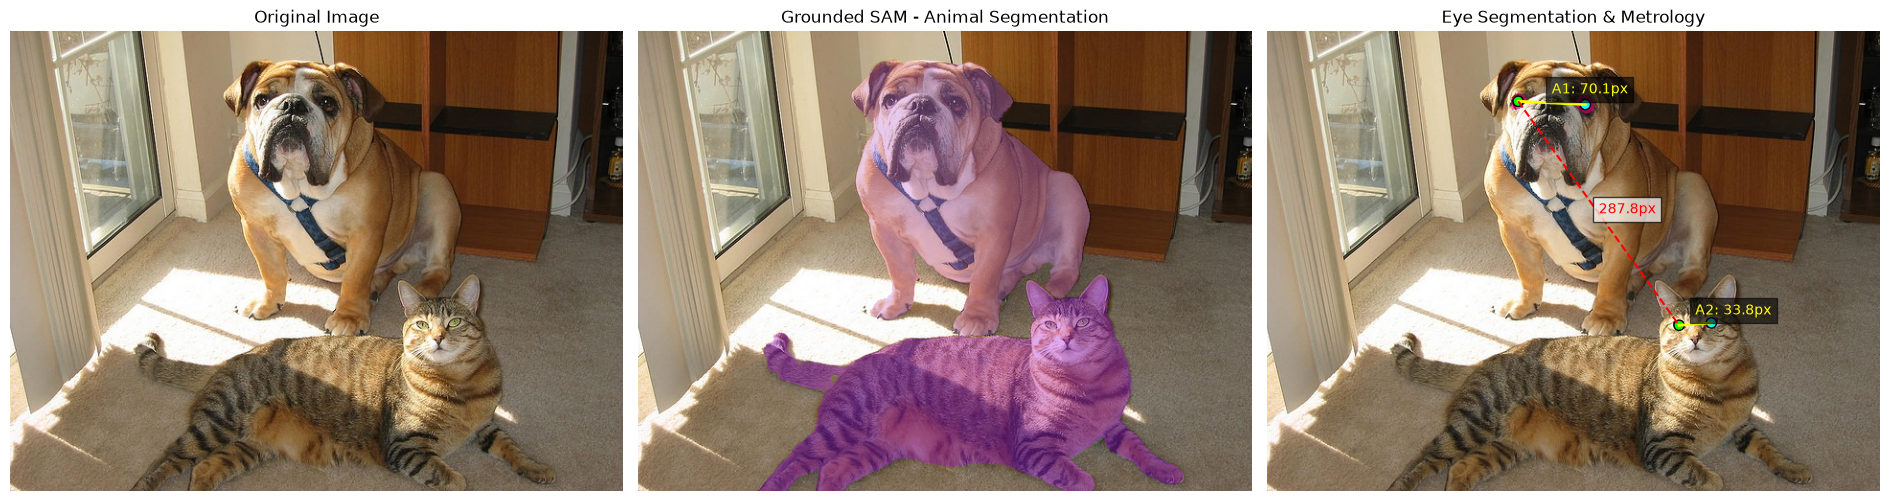

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

for ax in axes:
    ax.imshow(image_rgb)
    ax.axis("off")

axes[0].set_title("Original Image")
axes[1].set_title("Grounded SAM - Animal Segmentation")
axes[2].set_title("Eye Segmentation & Metrology")

rng = np.random.default_rng(42)

for animal in animals:
    color = rng.random(3)

    # Animal mask overlay
    rgba = np.zeros((H, W, 4))
    rgba[animal["mask"], :3] = color
    rgba[animal["mask"], 3] = 0.35

    axes[1].imshow(rgba)

    # Eye masks
    for eye_mask in animal["eye_masks"]:
        overlay = np.zeros((H, W, 4))
        overlay[eye_mask] = [1, 0, 0.5, 0.55]
        axes[2].imshow(overlay)

    lm = animal["landmarks"]

    if lm is None:
        continue

    right = lm["right_eye"]
    left = lm["left_eye"]

    axes[2].scatter(
        [right[0], left[0]],
        [right[1], left[1]],
        c=["lime", "cyan"],
        s=55,
        edgecolors="black"
    )

    d = distance(right, left)

    axes[2].plot(
        [right[0], left[0]],
        [right[1], left[1]],
        color="yellow",
        linewidth=2
    )

    mid_x = (right[0] + left[0]) / 2
    mid_y = (right[1] + left[1]) / 2

    axes[2].text(
        mid_x, mid_y - 10,
        f"A{animal['id']}: {d:.1f}px",
        color="yellow",
        fontsize=10,
        bbox={"facecolor": "black", "alpha": 0.6}
    )

# Plot all between-animal right-eye distances
for a1, a2 in combinations(valid_animals, 2):
    p1 = a1["landmarks"]["right_eye"]
    p2 = a2["landmarks"]["right_eye"]

    d = distance(p1, p2)

    axes[2].plot(
        [p1[0], p2[0]],
        [p1[1], p2[1]],
        "r--",
        linewidth=1.5
    )

    axes[2].text(
        (p1[0] + p2[0]) / 2,
        (p1[1] + p2[1]) / 2,
        f"{d:.1f}px",
        color="red",
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.7}
    )

plt.tight_layout()
plt.show()
